In [1]:
#import libraries
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns

In [2]:
#read data set
df = pd.read_csv('housing.csv')
#view first 5 rows
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
#number or rows and columns
df.shape

(20640, 10)

In [4]:
#view last 5 rows
df.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [5]:
#unique strings in ocean_proximity column
df.ocean_proximity.unique()

<StringArray>
['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND']
Length: 5, dtype: str

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


In [8]:
df.count()

longitude             20640
latitude              20640
housing_median_age    20640
total_rooms           20640
total_bedrooms        20433
population            20640
households            20640
median_income         20640
median_house_value    20640
ocean_proximity       20640
dtype: int64

In [9]:
#checking for null values
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [10]:
#dropping rows with null values
df.dropna(subset=['total_bedrooms'], inplace = True)

In [ ]:
#shape of the data frame after dropping rows with null values
df.shape

(20433, 10)

In [12]:
df.ocean_proximity.value_counts()

ocean_proximity
<1H OCEAN     9034
INLAND        6496
NEAR OCEAN    2628
NEAR BAY      2270
ISLAND           5
Name: count, dtype: int64

In [13]:
#duplicate check
df.duplicated().sum()

np.int64(0)

In [14]:
#correlation between variables
df[['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms',	'population', 'households',	'median_income', 'median_house_value']].corr()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924616,-0.109357,0.045480,0.069608,0.100270,0.056513,-0.015550,-0.045398
latitude,-0.924616,1.000000,0.011899,-0.036667,-0.066983,-0.108997,-0.071774,-0.079626,-0.144638
housing_median_age,-0.109357,0.011899,1.000000,-0.360628,-0.320451,-0.295787,-0.302768,-0.118278,0.106432
total_rooms,0.045480,-0.036667,-0.360628,1.000000,0.930380,0.857281,0.918992,0.197882,0.133294
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.100270,-0.108997,-0.295787,0.857281,0.877747,1.000000,0.907186,0.005087,-0.025300
households,0.056513,-0.071774,-0.302768,0.918992,0.979728,0.907186,1.000000,0.013434,0.064894
median_income,-0.015550,-0.079626,-0.118278,0.197882,-0.007723,0.005087,0.013434,1.000000,0.688355
median_house_value,-0.045398,-0.144638,0.106432,0.133294,0.049686,-0.025300,0.064894,0.688355,1.000000


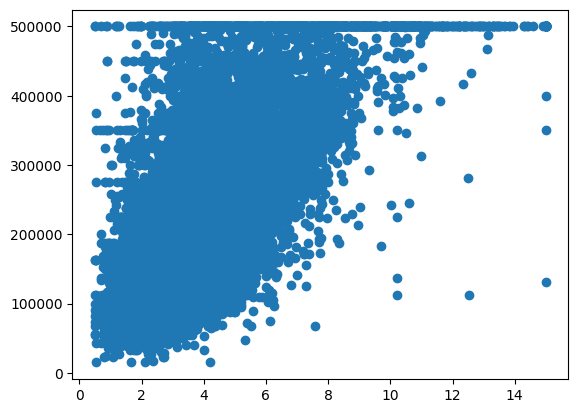

In [15]:
plt.scatter(df.median_income, df.median_house_value)

<Axes: xlabel='median_house_value'>

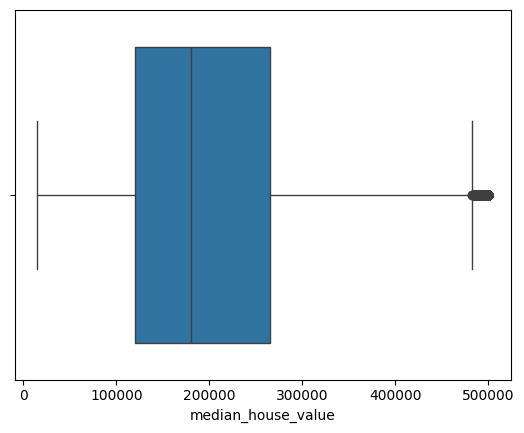

In [16]:
sns.boxplot(x=df['median_house_value'])

<Axes: xlabel='median_income'>

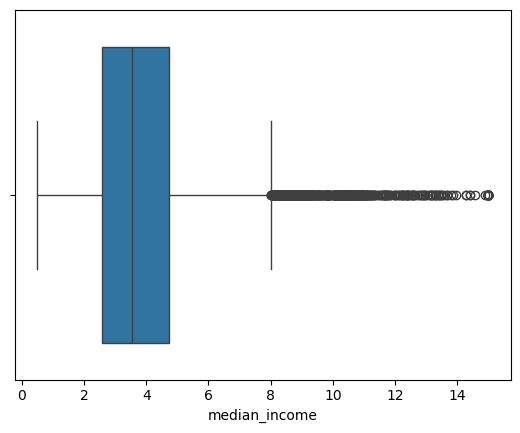

In [17]:
sns.boxplot(x=df.median_income)

In [18]:
#Elimanating outliners from median_house_value
df= df[df.median_house_value < 480000]

In [19]:
#Eliminating outliners from median income
df= df[df.median_income < 9]

In [20]:
#shape of cleaned dataset
df.shape

(19296, 10)

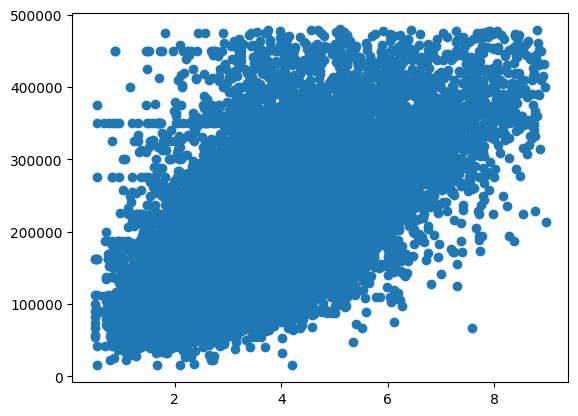

In [21]:
plt.scatter(df.median_income, df.median_house_value)

<Axes: xlabel='households'>

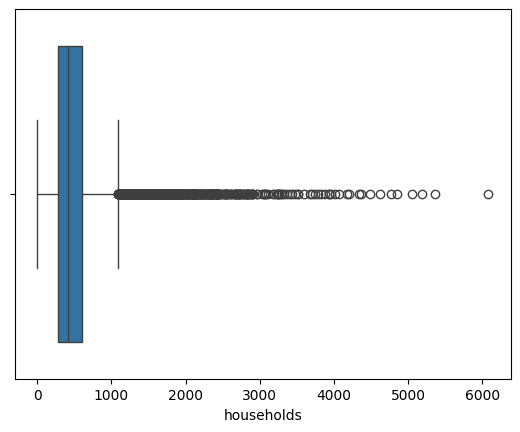

In [22]:
sns.boxplot(x=df.households)

plt.hist(df.median_house_value, bins=100, rwidth=0.8)
plt.xlabel('house value')

Text(0.5, 0, 'house value')

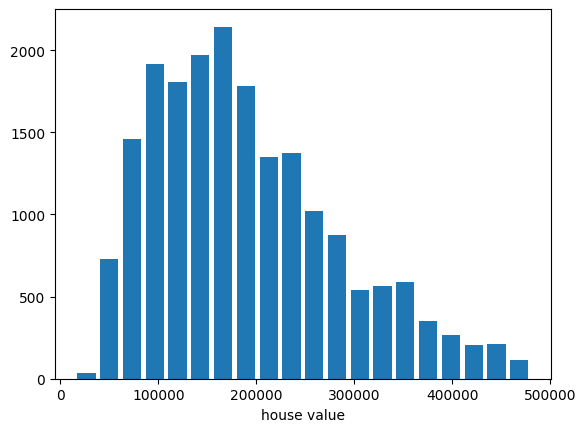

In [23]:
plt.hist(df.median_house_value, bins=20, rwidth=0.8)
plt.xlabel('house value')

Text(0.5, 0, 'median_income')

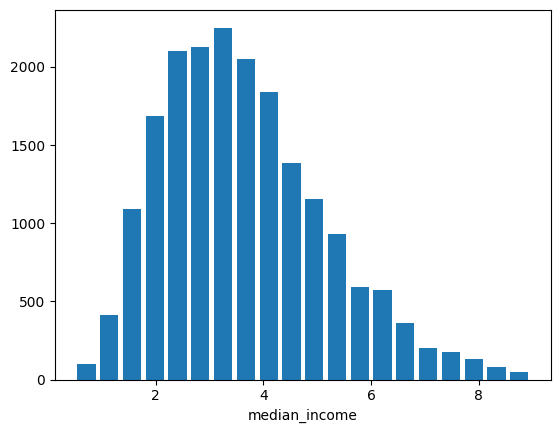

In [24]:
plt.hist(df.median_income, bins=20, rwidth=0.8)
plt.xlabel('median_income')

In [25]:
df.nunique()

longitude               842
latitude                861
housing_median_age       52
total_rooms            5750
total_bedrooms         1903
population             3853
households             1783
median_income         11947
median_house_value     3742
ocean_proximity           5
dtype: int64

In [26]:
#correlations
df[['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms',	'population', 'households',	'median_income', 'median_house_value']].corr()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.923861,-0.102530,0.044392,0.070080,0.102210,0.057029,-0.012248,-0.049216
latitude,-0.923861,1.000000,0.006145,-0.033080,-0.068258,-0.114735,-0.073861,-0.077028,-0.148753
housing_median_age,-0.102530,0.006145,1.000000,-0.372002,-0.329183,-0.295738,-0.311161,-0.194988,0.069009
total_rooms,0.044392,-0.033080,-0.372002,1.000000,0.934769,0.860850,0.922242,0.235107,0.145984
total_bedrooms,0.070080,-0.068258,-0.329183,0.934769,1.000000,0.880110,0.979152,0.033079,0.081484
population,0.102210,-0.114735,-0.295738,0.860850,0.880110,1.000000,0.909969,0.052396,0.018672
households,0.057029,-0.073861,-0.311161,0.922242,0.979152,0.909969,1.000000,0.058774,0.101287
median_income,-0.012248,-0.077028,-0.194988,0.235107,0.033079,0.052396,0.058774,1.000000,0.641651
median_house_value,-0.049216,-0.148753,0.069009,0.145984,0.081484,0.018672,0.101287,0.641651,1.000000


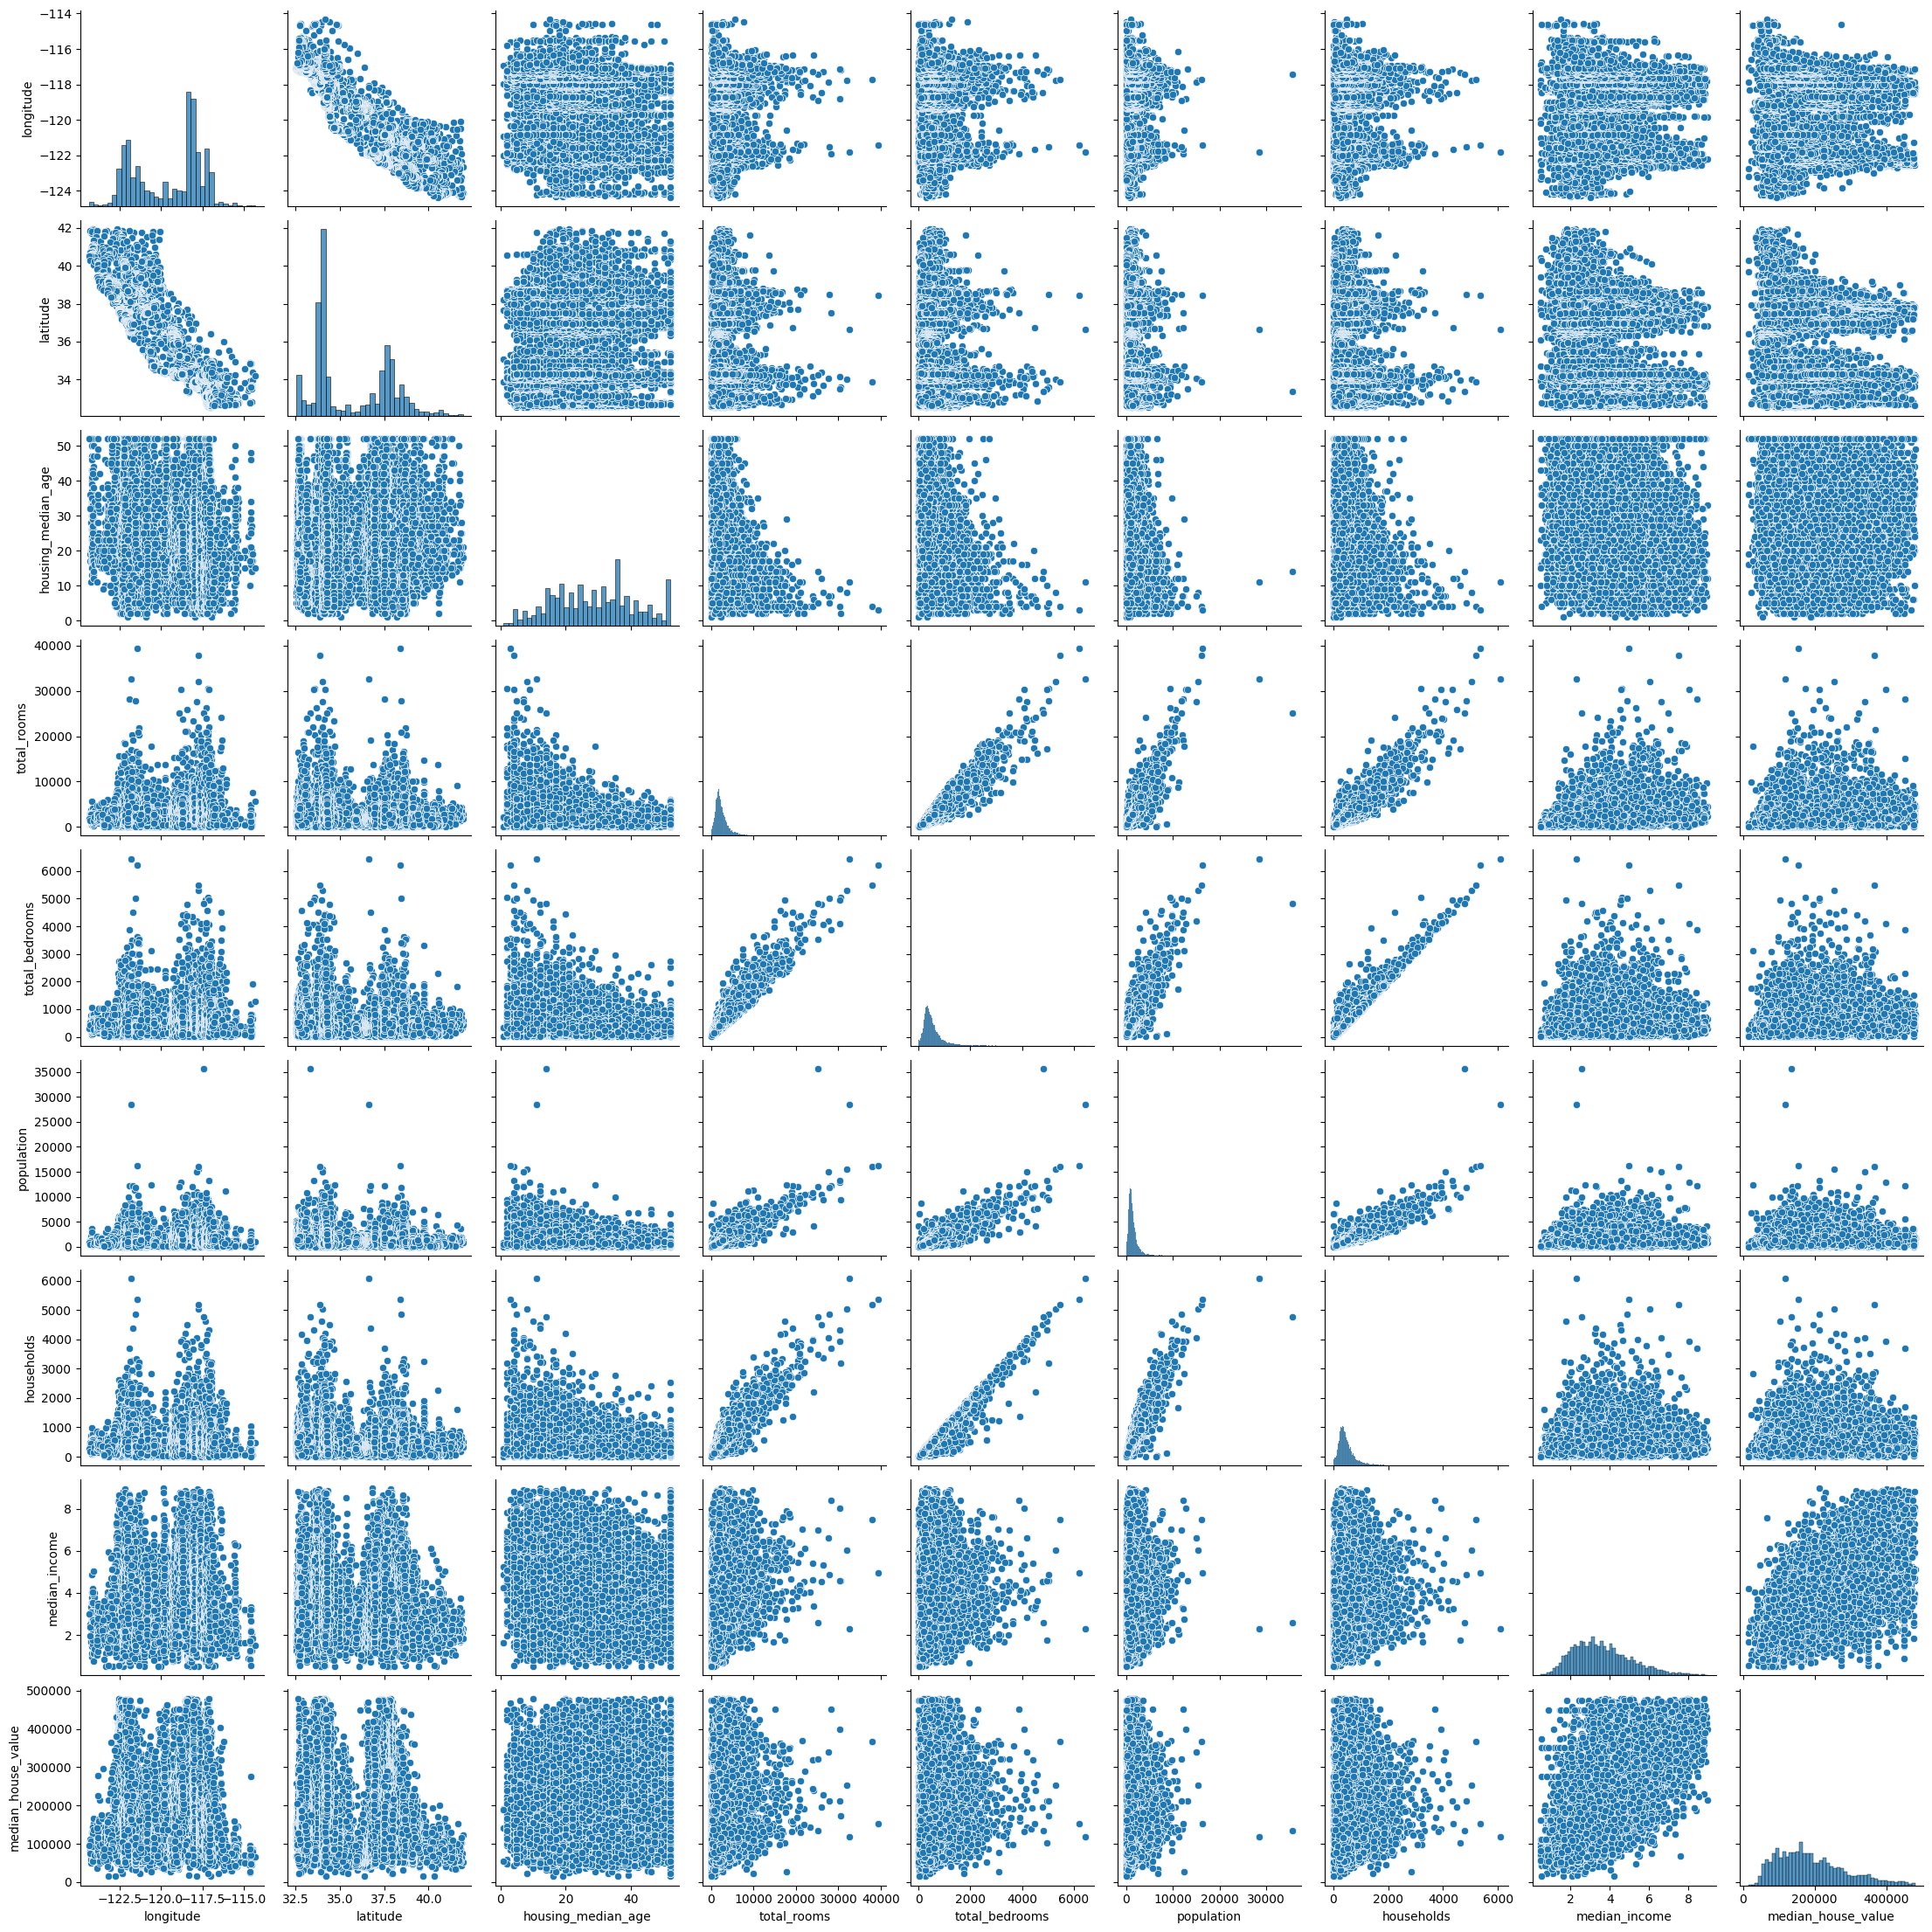

In [27]:
sns.pairplot(df)

Machine Learning Model

In [28]:
dummies = pd.get_dummies(df.ocean_proximity)
dummies= dummies.astype(int)
dummies

,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
0,0,0,0,1,0
1,0,0,0,1,0
2,0,0,0,1,0
3,0,0,0,1,0
4,0,0,0,1,0
...,...,...,...,...,...
20635,0,1,0,0,0
20636,0,1,0,0,0
20637,0,1,0,0,0
20638,0,1,0,0,0


In [29]:
dfMerge= pd.concat([df,dummies], axis='columns')
dfMerge

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND,0,1,0,0,0
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND,0,1,0,0,0
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND,0,1,0,0,0
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND,0,1,0,0,0


In [30]:
final_df = dfMerge.drop(['longitude', 'latitude', 'housing_median_age',	'total_rooms', 'total_bedrooms', 'population',	'households', 'ocean_proximity', '<1H OCEAN'], axis='columns')
final_df

,median_income,median_house_value,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
0,8.3252,452600.0,0,0,1,0
1,8.3014,358500.0,0,0,1,0
2,7.2574,352100.0,0,0,1,0
3,5.6431,341300.0,0,0,1,0
4,3.8462,342200.0,0,0,1,0
...,...,...,...,...,...,...
20635,1.5603,78100.0,1,0,0,0
20636,2.5568,77100.0,1,0,0,0
20637,1.7000,92300.0,1,0,0,0
20638,1.8672,84700.0,1,0,0,0


Linear Regression model

In [31]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()

In [32]:
X = final_df.drop(['median_house_value'], axis = 'columns')
X

,median_income,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
0,8.3252,0,0,1,0
1,8.3014,0,0,1,0
2,7.2574,0,0,1,0
3,5.6431,0,0,1,0
4,3.8462,0,0,1,0
...,...,...,...,...,...
20635,1.5603,1,0,0,0
20636,2.5568,1,0,0,0
20637,1.7000,1,0,0,0
20638,1.8672,1,0,0,0


In [33]:
y = final_df.median_house_value
y

0        452600.0
1        358500.0
2        352100.0
3        341300.0
4        342200.0
           ...   
20635     78100.0
20636     77100.0
20637     92300.0
20638     84700.0
20639     89400.0
Name: median_house_value, Length: 19296, dtype: float64

In [34]:
model.fit(X,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [35]:
linear_regression_model= model.predict([[5.6,0,0,0,0]])

c:\Users\user\miniconda3\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


Train Test Split

In [36]:
from sklearn.model_selection import train_test_split

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2, random_state= 42)

In [38]:
len(X_train)

15436

In [39]:
len(X_test)

3860

In [40]:
from sklearn.linear_model import LinearRegression
model= LinearRegression()

In [41]:
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [42]:
predict = model.predict(X_test)
predict

array([148142.71760021, 273493.42968069, 243249.1338698 , ...,
       160269.00539262, 125980.81070045, 236477.59897291], shape=(3860,))

In [43]:
model.score(X_test, y_test)

0.5501072689367703

In [44]:
comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted': predict
})

print(comparison.head(10))

         Actual      Predicted
203    119400.0  148142.717600
1382   199900.0  273493.429681
8035   336000.0  243249.133870
9457   145800.0  150318.974104
18742   67900.0   82947.188978
8956   304100.0  249793.449751
11339  174100.0  228582.415196
349     88800.0  177795.989935
14418  193800.0  211287.957771
16506  125900.0  127804.924525


In [45]:
y_test.iloc[203]

np.float64(260900.0)

In [46]:
train_test_model= model.predict([[3.1094,1,0,0,0]])

c:\Users\user\miniconda3\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [47]:
print('linear_regression_model', linear_regression_model)
print('train_test_model', train_test_model)

linear_regression_model [279513.99742622]
train_test_model [120550.64526755]


In [48]:
df1 = df[df.ocean_proximity == 'NEAR OCEAN']
df1

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
1850,-124.17,41.80,16.0,2739.0,480.0,1259.0,436.0,3.7557,109400.0,NEAR OCEAN
1851,-124.30,41.80,19.0,2672.0,552.0,1298.0,478.0,1.9797,85800.0,NEAR OCEAN
1852,-124.23,41.75,11.0,3159.0,616.0,1343.0,479.0,2.4805,73200.0,NEAR OCEAN
1853,-124.21,41.77,17.0,3461.0,722.0,1947.0,647.0,2.5795,68400.0,NEAR OCEAN
1854,-124.19,41.78,15.0,3140.0,714.0,1645.0,640.0,1.6654,74600.0,NEAR OCEAN
...,...,...,...,...,...,...,...,...,...,...
20379,-118.83,34.15,16.0,3380.0,731.0,1227.0,641.0,4.2857,233200.0,NEAR OCEAN
20381,-118.83,34.14,16.0,1956.0,312.0,671.0,319.0,6.4001,321800.0,NEAR OCEAN
20423,-119.00,34.08,17.0,1822.0,438.0,578.0,291.0,5.4346,428600.0,NEAR OCEAN
20424,-118.75,34.18,4.0,16704.0,2704.0,6187.0,2207.0,6.6122,357600.0,NEAR OCEAN


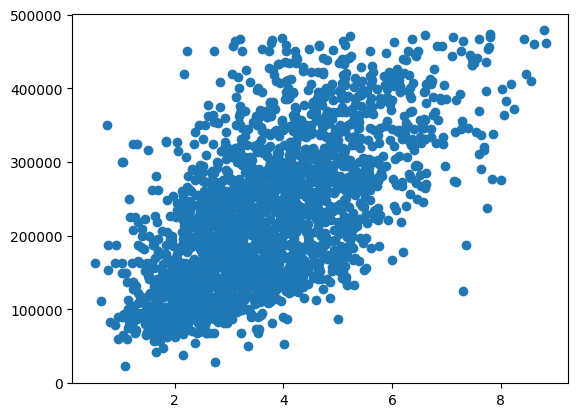

In [49]:
plt.scatter(df1.median_income, df1.median_house_value)